In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import os
print(os.getcwd())

C:\Users\ganav


In [5]:
print(os.listdir())

['.anaconda', '.cache', '.codex', '.conda', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.vscode', '.vscode-shared', 'anaconda3', 'Analysing-pharmaceutical-sales-data', 'AppData', 'Application Data', 'Arrays.ipynb', 'Contacts', 'Cookies', 'Data_analysis', 'Documents', 'Downloads', 'Favorites', 'file', 'job_listings.csv', 'Job_Listing_Web_Scraper.ipynb', 'Links', 'Local Settings', 'Matplotlib (1).ipynb', 'Matplotlibyb.ipynb', 'Microsoft', 'Music', 'My Documents', 'my_array.npy', 'Netflix project', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{9ce4fa15-b238-11f1-840e-fdc63eef6d50}.TM.blf', 'NTUSER.DAT{9ce4fa15-b238-11f1-840e-fdc63eef6d50}.TM.blf.cnpf', 'NTUSER.DAT{9ce4fa15-b238-11f1-840e-fdc63eef6d50}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{9ce4fa15-b238-11f1-840e-fdc63eef6d50}.TMContainer00000000000000000001.regtrans-ms.cnpf', 'NTUSER.DAT{9ce4fa15-b238-11f1-840e-fdc63eef6d50}.TMContainer00000000000000000002.regtr

In [6]:
import os

print(os.listdir("Analysing-pharmaceutical-sales-data"))

['Data']


In [8]:
df = pd.read_csv("Analysing-pharmaceutical-sales-data/data/salesdaily.csv")

df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (2106, 13)

Column Names:
['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06', 'Year', 'Month', 'Hour', 'Weekday Name']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   str    
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   str    
dtypes: float64(8), int64(3), str(2)
memory usage: 247.1 KB


In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64

Duplicate Rows:
0


In [11]:
df["datum"] = pd.to_datetime(df["datum"])

print(df["datum"].dtype)

datetime64[us]


In [12]:
drug_columns = ["M01AB", "M01AE", "N02BA", "N02BE",
                "N05B", "N05C", "R03", "R06"]

total_sales = df[drug_columns].sum()

print(total_sales)

M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
N02BE    63005.402708
N05B     18645.737500
N05C      1249.958333
R03      11608.822917
R06       6107.817500
dtype: float64


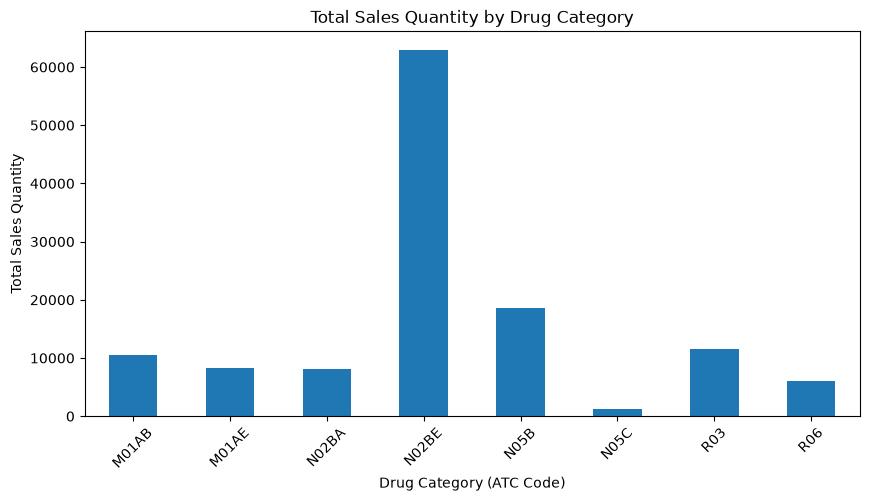

In [27]:
plt.figure(figsize=(10, 5))

total_sales.plot(kind="bar")

plt.title("Total Sales Quantity by Drug Category")
plt.xlabel("Drug Category (ATC Code)")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=45)

plt.show()

In [16]:
top_categories = total_sales.sort_values(ascending=False)

print("Drug Categories Ranked by Total Sales:")
print(top_categories)

Drug Categories Ranked by Total Sales:
N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


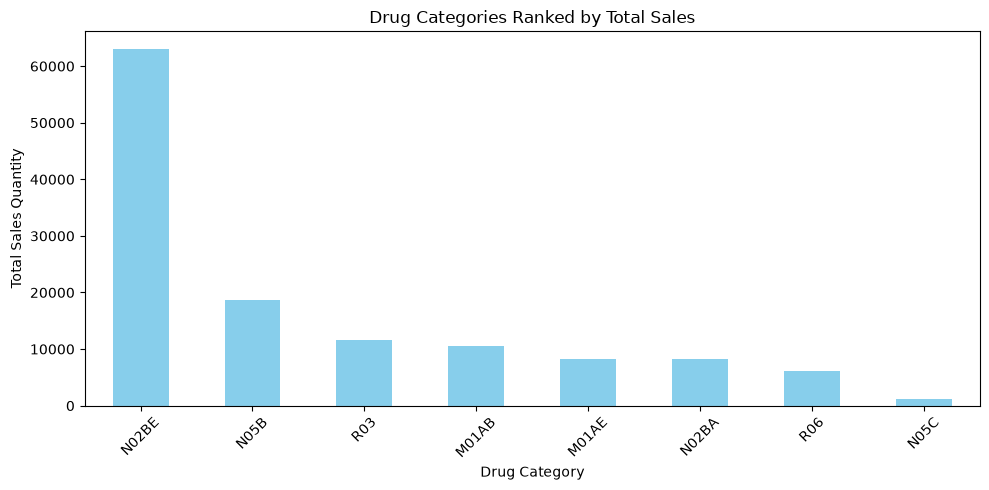

In [17]:
plt.figure(figsize=(10, 5))

top_categories.plot(kind="bar", color="skyblue")

plt.title("Drug Categories Ranked by Total Sales")
plt.xlabel("Drug Category")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
jan_2015 = df[
    (df["datum"].dt.year == 2015) &
    (df["datum"].dt.month == 1)
]

In [31]:
jan_sales = jan_2015[drug_columns].sum()

jan_top3 = jan_sales.sort_values(
    ascending=False
).head(3)

print("Top 3 Drug Categories - January 2015:")
print(jan_top3)

Top 3 Drug Categories - January 2015:
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64


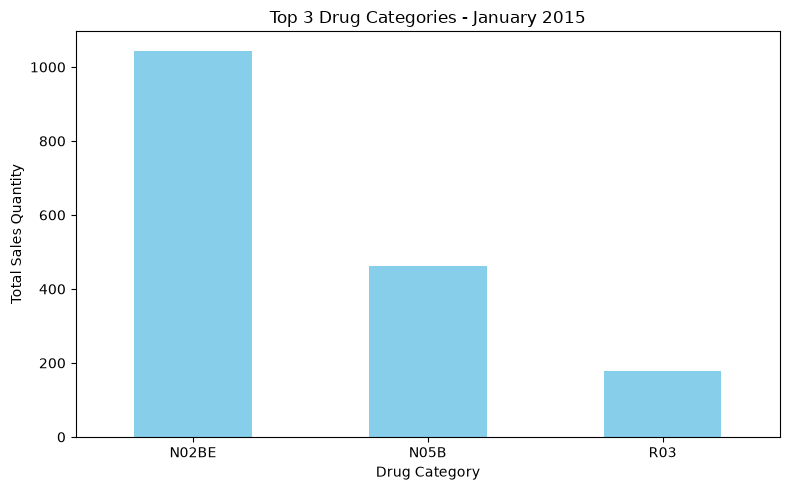

In [32]:
plt.figure(figsize=(8, 5))

jan_top3.plot(kind="bar", color="skyblue")

plt.title("Top 3 Drug Categories - January 2015")
plt.xlabel("Drug Category")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [33]:
july_2016 = df[
    (df["datum"].dt.year == 2016) &
    (df["datum"].dt.month == 7)
]
july_sales = july_2016[drug_columns].sum()

july_top3 = july_sales.sort_values(
    ascending=False
).head(3)

print("Top 3 Drug Categories - July 2016:")
print(july_top3)

Top 3 Drug Categories - July 2016:
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64


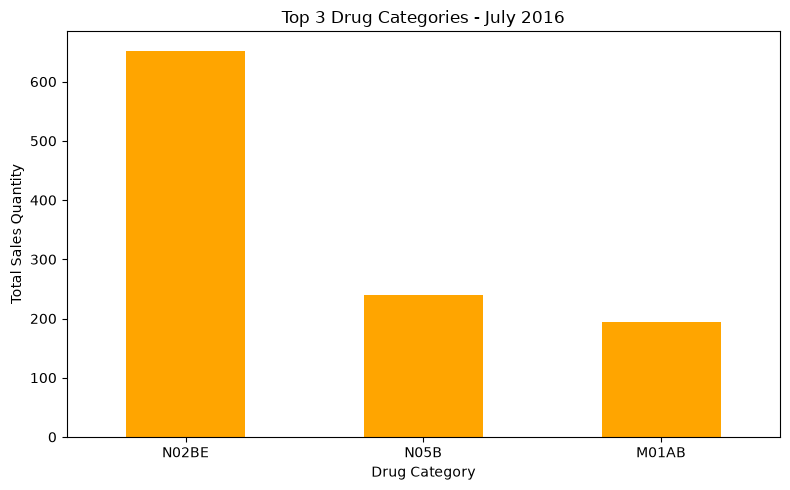

In [34]:
plt.figure(figsize=(8, 5))

july_top3.plot(kind="bar", color="orange")

plt.title("Top 3 Drug Categories - July 2016")
plt.xlabel("Drug Category")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [35]:
sept_2017 = df[
    (df["datum"].dt.year == 2017) &
    (df["datum"].dt.month == 9)
]
sept_sales = sept_2017[drug_columns].sum()

sept_top3 = sept_sales.sort_values(
    ascending=False
).head(3)

print("Top 3 Drug Categories - September 2017:")
print(sept_top3)

Top 3 Drug Categories - September 2017:
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


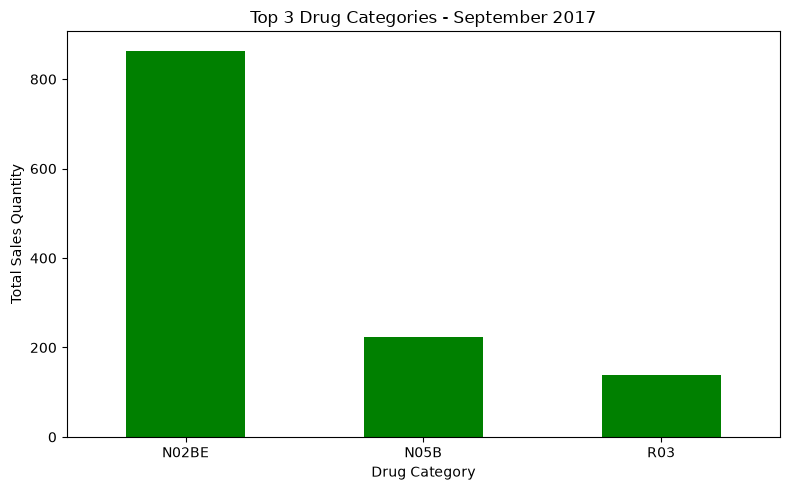

In [36]:
plt.figure(figsize=(8, 5))

sept_top3.plot(kind="bar", color="green")

plt.title("Top 3 Drug Categories - September 2017")
plt.xlabel("Drug Category")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [37]:
sales_2017 = df[df["datum"].dt.year == 2017]

print("Total records in 2017:", len(sales_2017))

Total records in 2017: 365


In [38]:
sales_2017_total = sales_2017[drug_columns].sum()

top_2017 = sales_2017_total.sort_values(ascending=False)

print("Drug Categories Ranked by Sales in 2017:")
print(top_2017)

Drug Categories Ranked by Sales in 2017:
N02BE    9258.804833
N05B     2555.541667
R03      1893.614583
M01AB    1846.617083
M01AE    1387.298333
N02BA    1288.295833
R06       988.860000
N05C      180.333333
dtype: float64


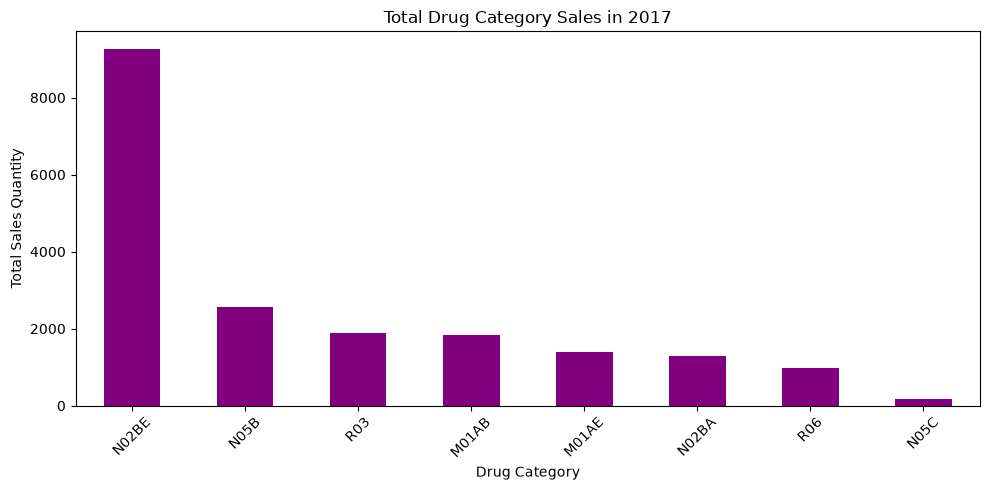

In [39]:
plt.figure(figsize=(10, 5))

top_2017.plot(kind="bar", color="purple")

plt.title("Total Drug Category Sales in 2017")
plt.xlabel("Drug Category")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [40]:
average_sales = df[drug_columns].mean()

print("Average Daily Sales by Drug Category:")
print(average_sales)

Average Daily Sales by Drug Category:
M01AB     5.033683
M01AE     3.895830
N02BA     3.880441
N02BE    29.917095
N05B      8.853627
N05C      0.593522
R03       5.512262
R06       2.900198
dtype: float64


In [41]:
average_sales_ranked = average_sales.sort_values(
    ascending=False
)

print("Drug Categories Ranked by Average Daily Sales:")
print(average_sales_ranked)

Drug Categories Ranked by Average Daily Sales:
N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
N02BA     3.880441
R06       2.900198
N05C      0.593522
dtype: float64


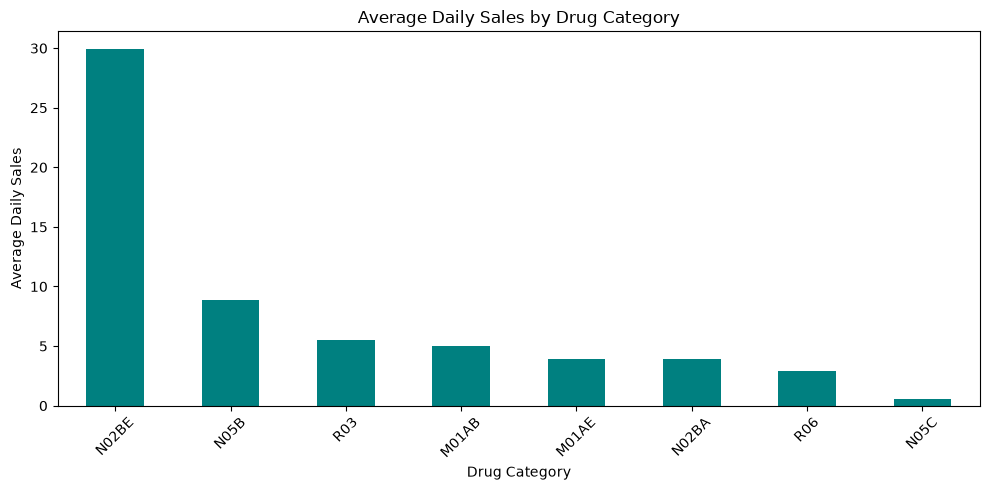

In [42]:
plt.figure(figsize=(10, 5))

average_sales_ranked.plot(kind="bar", color="teal")

plt.title("Average Daily Sales by Drug Category")
plt.xlabel("Drug Category")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
monthly_r03 = df.groupby("Month")["R03"].mean()

print("Average Daily R03 Sales by Month:")
print(monthly_r03)

Average Daily R03 Sales by Month:
Month
1     6.835980
2     6.896943
3     6.290323
4     5.771528
5     5.006944
6     4.350000
7     2.956989
8     3.102151
9     4.402315
10    7.208589
11    6.226667
12    7.916129
Name: R03, dtype: float64


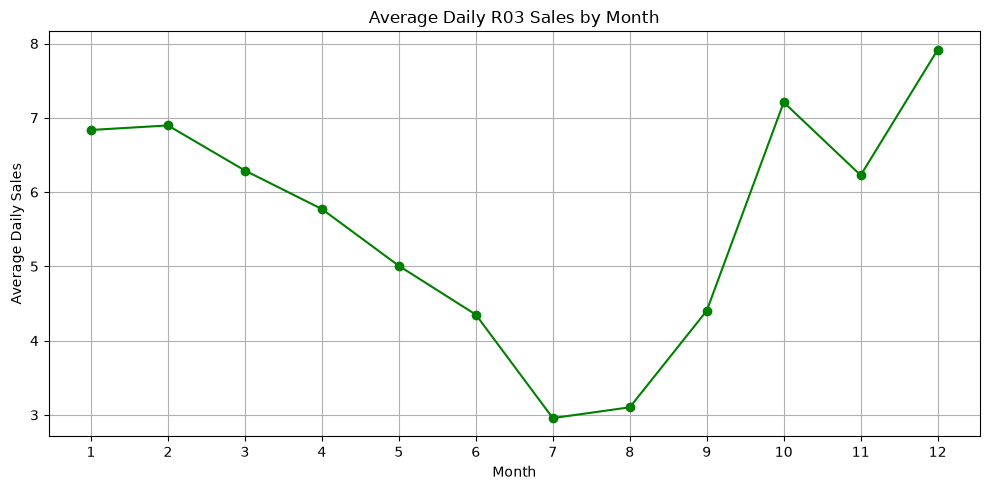

In [44]:
plt.figure(figsize=(10, 5))

monthly_r03.plot(kind="line", marker="o", color="green")

plt.title("Average Daily R03 Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")

plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()